# 04 · Evaluation

We compare four strategies on a **common** set of simulated return paths (common random numbers):

* **DP optimal** — the interpolated dynamic-programming policy;
* **ML imitation** — the trained network;
* **Periodic** — rebalance to $w^\*$ every few steps;
* **Buy & hold** — trade to $w^\*$ once, then never.

Metrics: terminal wealth, expected utility / certainty equivalent, turnover, transaction cost, and tracking error vs the optimal policy.

In [1]:
import os, sys
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt


In [2]:
from src.config import Config
from src.dp_solver import solve
from src.ml_policy import train_policy
from src.simulation import run_all_strategies, results_table, paired_comparison
from src import visualization as viz
# Lighter settings for a quick notebook run.
cfg = Config(n_paths=6000, ml_epochs=150)
sol = solve(cfg)
model, _ = train_policy(sol, cfg)
results = run_all_strategies(cfg, sol, model)
summary = results_table(results, cfg.gamma)
df = pd.DataFrame(summary)[['strategy','certainty_equivalent','ce_ci_low',
    'ce_ci_high','mean_terminal_wealth','mean_turnover','mean_total_cost','tracking_error']]
df.round(5)

,strategy,certainty_equivalent,ce_ci_low,ce_ci_high,mean_terminal_wealth,mean_turnover,mean_total_cost,tracking_error
0,DP optimal,1.02963,1.02806,1.03121,1.03955,0.00002,0.00000,NaN
1,ML imitation,1.02544,1.02350,1.02740,1.03957,0.28211,0.00286,0.00670
2,Periodic,1.02855,1.02696,1.03014,1.03797,0.11222,0.00115,0.00562
3,Buy & hold,1.02963,1.02806,1.03121,1.03955,0.00000,0.00000,0.00009


## Terminal-wealth distributions

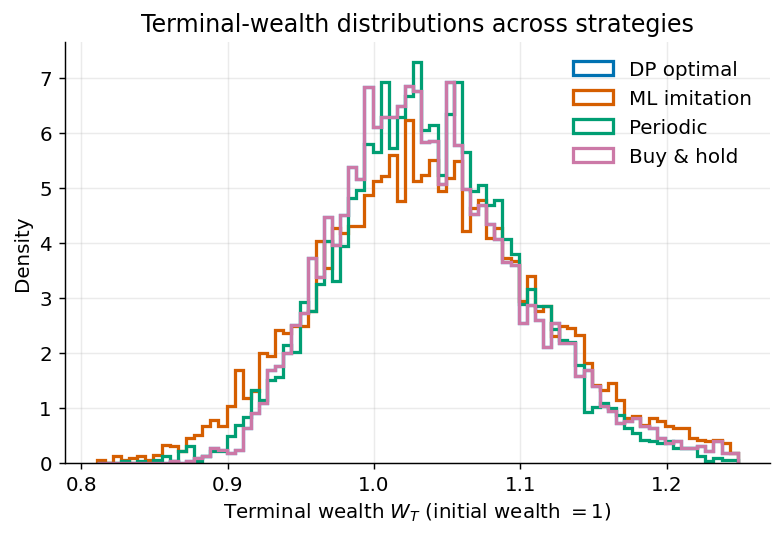

In [3]:
viz.plot_wealth_distributions(results); plt.show()

## Performance bars (certainty equivalent with 95% CI, turnover, cost)

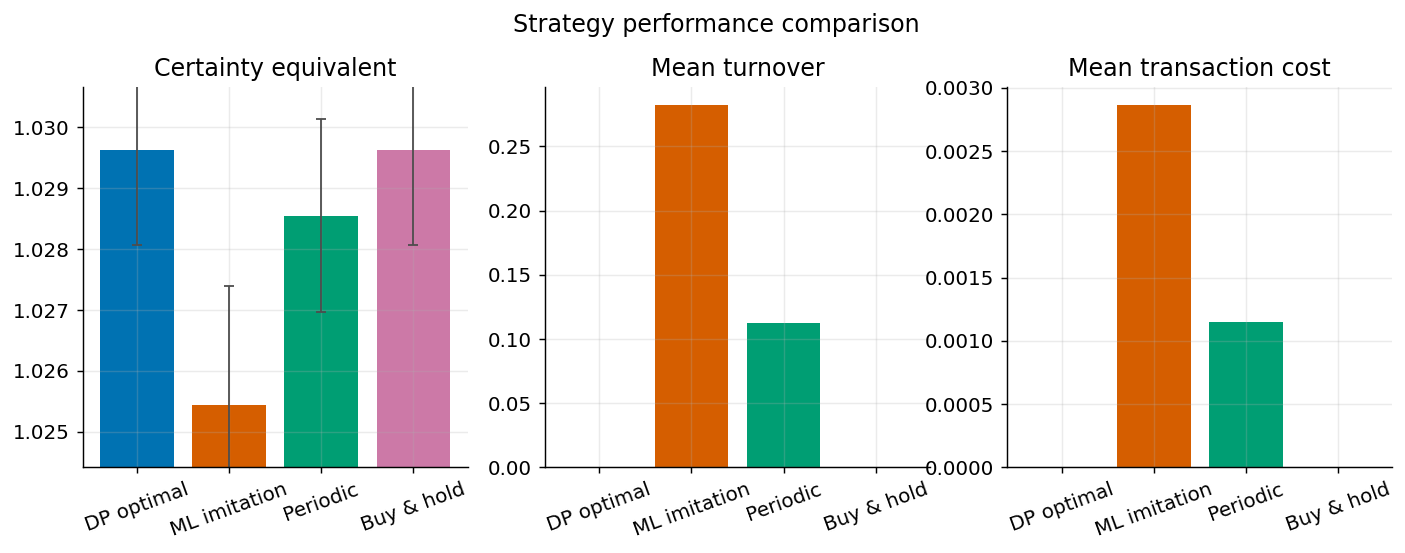

In [4]:
viz.plot_performance_bars(summary); plt.show()

## Is DP *significantly* better? Paired test with common random numbers
Because every strategy sees the same returns, the per-path utility differences have far smaller variance than the individual estimates, giving a powerful paired test.

In [5]:
pd.DataFrame(paired_comparison(results, 'DP optimal')).round(6)

,reference,vs,mean_utility_advantage,se,t_stat,ci_low,ci_high,reference_better_95pct
0,DP optimal,ML imitation,0.003657,0.000264,13.875376,0.003140,0.004174,True
1,DP optimal,Periodic,0.000939,0.000069,13.622502,0.000804,0.001075,True
2,DP optimal,Buy & hold,0.000001,0.000000,1.250313,-0.000000,0.000001,False


**Reading the table.** DP beats ML and Periodic with large $t$-statistics. DP vs Buy & hold is *not* significant when we start at the target — economically correct, since the wide no-trade band makes optimal behaviour ≈ "do nothing" here.

## Starting away from the target
When the initial allocation is far from $w^\*$, rebalancing matters and DP dominates *all* baselines by trading in most cost-efficiently.

In [6]:
from src.simulation import (simulate_strategy, make_dp_action, make_ml_action,
    make_periodic_action, make_buy_hold_action)
from src.dynamics import sample_gross_returns
rng = np.random.default_rng(cfg.seed+7)
returns = sample_gross_returns(cfg, (cfg.n_paths, cfg.n_steps), rng)
x0 = 0.80
acts = {'DP optimal':(make_dp_action(sol),None),
        'ML imitation':(make_ml_action(model,cfg),sol),
        'Periodic':(make_periodic_action(cfg),sol),
        'Buy & hold':(make_buy_hold_action(cfg),sol)}
off = {n: simulate_strategy(cfg,a,returns,n,dp_for_tracking=t,initial_fraction=x0)
       for n,(a,t) in acts.items()}
pd.DataFrame(results_table(off, cfg.gamma))[['strategy','certainty_equivalent',
    'mean_turnover','mean_total_cost','tracking_error']].round(5)

,strategy,certainty_equivalent,mean_turnover,mean_total_cost,tracking_error
0,DP optimal,1.02380,0.45260,0.00453,NaN
1,ML imitation,1.01986,0.77592,0.00779,0.00859
2,Periodic,1.02261,0.61226,0.00614,0.01005
3,Buy & hold,1.02363,0.50000,0.00500,0.00832


In [7]:
pd.DataFrame(paired_comparison(off, 'DP optimal')).round(6)

,reference,vs,mean_utility_advantage,se,t_stat,ci_low,ci_high,reference_better_95pct
0,DP optimal,ML imitation,0.003538,0.000207,17.070684,0.003132,0.003944,True
1,DP optimal,Periodic,0.001061,0.000118,8.990623,0.000829,0.001292,True
2,DP optimal,Buy & hold,0.000146,0.000127,1.145984,-0.000104,0.000395,False


**Conclusions.**
1. The DP policy is statistically the best strategy (or tied with buy & hold when starting on target).
2. The ML imitation, despite a tiny action-space error, **over-trades** (highest turnover and cost) because it cannot reproduce the no-trade region — it is the *worst* performer by certainty equivalent.
3. Periodic rebalancing wastes cost on unnecessary trades; buy & hold is surprisingly strong over a one-year horizon when started on target.

The practical lesson: imitating optimal *control* requires respecting the inaction region, not just minimizing action-space MSE. See the paper's Discussion for cost-aware and dead-zone remedies.